<center><h1>Meyyappan_Shammu_HW5</h1></center>
<br>
<br>

Name: Shammu Meyyappan
<br>
Github Username: ShammuMeyyappan
<br>
USC ID: 4085790637

## 1. Decision Trees as Interpretable Models

Import packages

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, KFold, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [31]:
cols = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
        "micturition_pains", "burning_urethra",
        "inflammation", "nephritis"]

df = pd.read_csv("../data/diagnosis.data", encoding="utf-16",
                 sep="\t", header=None, decimal=",", names=cols)

for c in cols[1:]:
    df[c] = (df[c] == "yes").astype(int)

print(df.shape)
df.head()

(120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

Training accuracy: 1.0
Depth: 4 | Leaves: 6


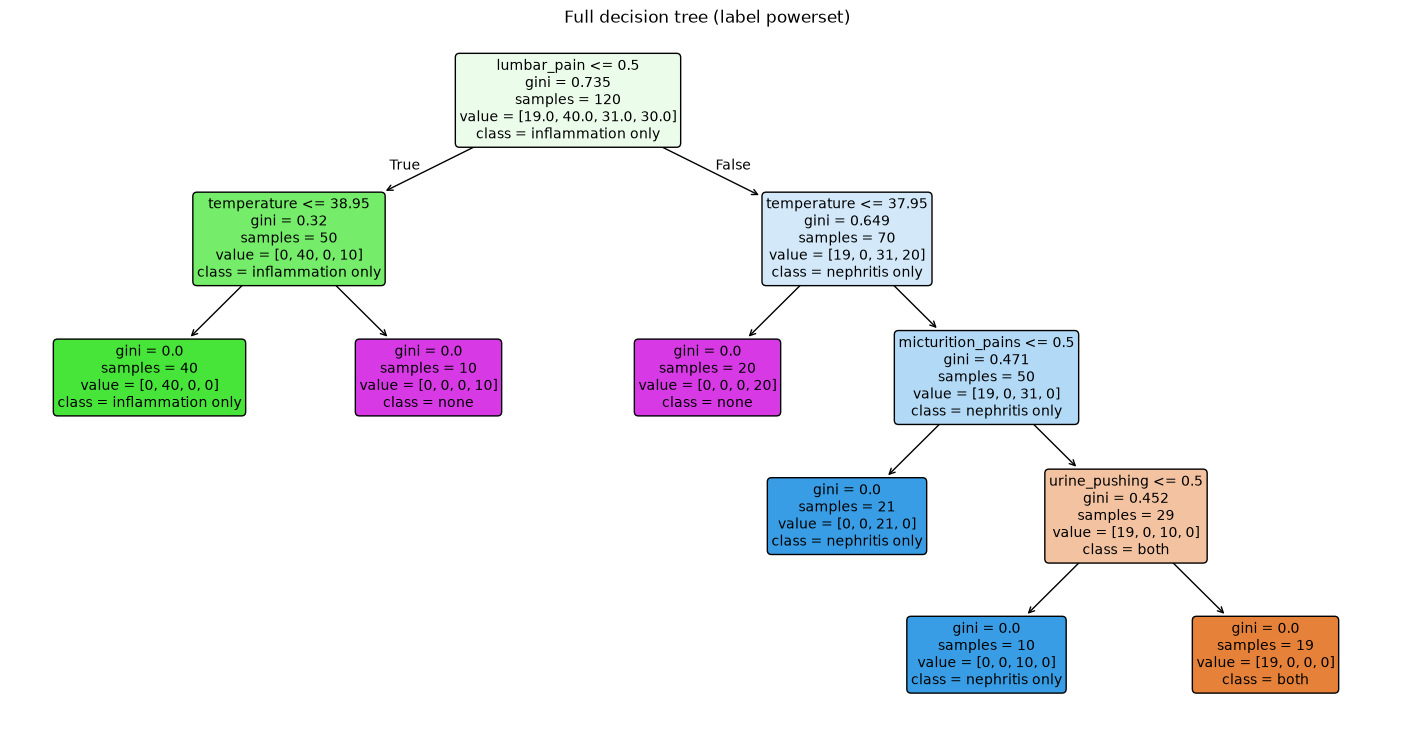

In [32]:
def make_class(row):
    if row["inflammation"] == 1 and row["nephritis"] == 1:
        return "both"
    elif row["inflammation"] == 1:
        return "inflammation only"
    elif row["nephritis"] == 1:
        return "nephritis only"
    else:
        return "none"

df["diagnosis"] = df.apply(make_class, axis=1)

features = cols[:6]
X1 = df[features]
y1 = df["diagnosis"]

tree_full = DecisionTreeClassifier(random_state=0)
tree_full.fit(X1, y1)

print("Training accuracy:", tree_full.score(X1, y1))
print("Depth:", tree_full.get_depth(), "| Leaves:", tree_full.get_n_leaves())

plt.figure(figsize=(18, 9))
plot_tree(tree_full, feature_names=features, class_names=tree_full.classes_,
          filled=True, rounded=True, fontsize=10)
plt.title("Full decision tree (label powerset)")
plt.show()

### (c) Convert the decision rules

In [33]:
def tree_to_rules(model, feature_names):
    t = model.tree_
    rules = []

    def walk(node, conditions):
        if t.feature[node] != -2:
            name = feature_names[t.feature[node]]
            thr = t.threshold[node]
            if name == "temperature":
                left  = f"{name} <= {thr:.2f}"
                right = f"{name} > {thr:.2f}"
            else:
                left  = f"{name} = no"
                right = f"{name} = yes"
            walk(t.children_left[node],  conditions + [left])
            walk(t.children_right[node], conditions + [right])
        else:
            label = model.classes_[t.value[node].argmax()]
            n = t.n_node_samples[node]
            rules.append("IF " + " AND ".join(conditions) +
                         f"  THEN {label}   ({n} patients)")

    walk(0, [])
    return rules

rules_full = tree_to_rules(tree_full, features)
for i, r in enumerate(rules_full, 1):
    print(f"Rule {i}: {r}")

Rule 1: IF lumbar_pain = no AND temperature <= 38.95  THEN inflammation only   (40 patients)
Rule 2: IF lumbar_pain = no AND temperature > 38.95  THEN none   (10 patients)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95  THEN none   (20 patients)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no  THEN nephritis only   (21 patients)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no  THEN nephritis only   (10 patients)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes  THEN both   (19 patients)


### (d) Cost-complexity pruning

Best alpha: 0.0
CV accuracy: 0.9917
Leaves: 6


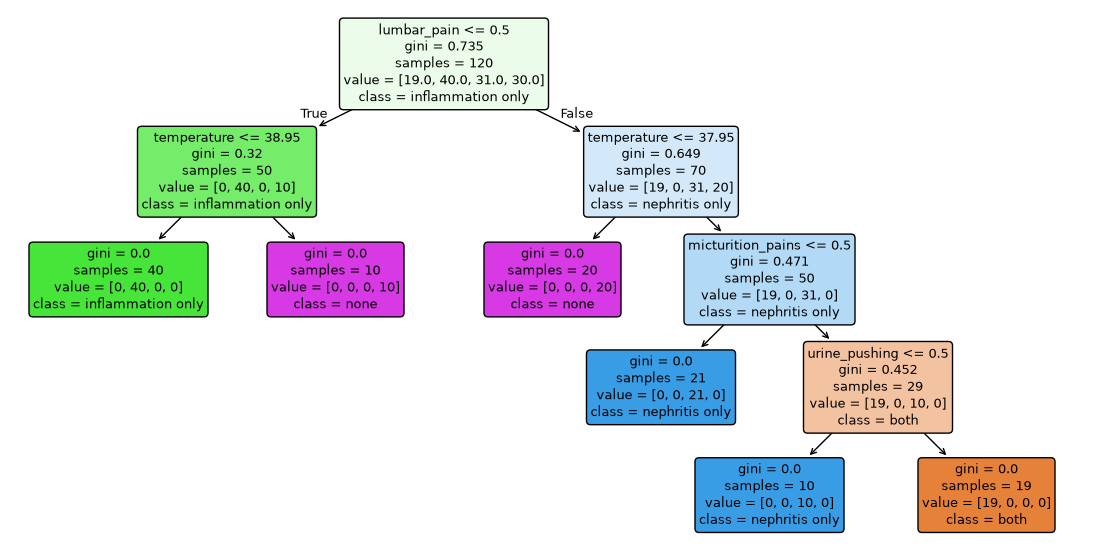

Rule 1: IF lumbar_pain = no AND temperature <= 38.95  THEN inflammation only   (40 patients)
Rule 2: IF lumbar_pain = no AND temperature > 38.95  THEN none   (10 patients)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95  THEN none   (20 patients)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no  THEN nephritis only   (21 patients)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no  THEN nephritis only   (10 patients)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes  THEN both   (19 patients)


In [34]:
path = tree_full.cost_complexity_pruning_path(X1, y1)
alphas = path.ccp_alphas[:-1]

search = GridSearchCV(DecisionTreeClassifier(random_state=0),
                      {"ccp_alpha": alphas},
                      cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0))
search.fit(X1, y1)

tree_pruned = search.best_estimator_
print("Best alpha:", search.best_params_["ccp_alpha"])
print("CV accuracy:", round(search.best_score_, 4))
print("Leaves:", tree_pruned.get_n_leaves())

plt.figure(figsize=(14, 7))
plot_tree(tree_pruned, feature_names=features, class_names=tree_pruned.classes_,
          filled=True, rounded=True)
plt.show()

for i, r in enumerate(tree_to_rules(tree_pruned, features), 1):
    print(f"Rule {i}: {r}")

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [35]:
names = []
with open("../data/communities.names") as f:
    for line in f:
        if line.startswith("@attribute"):
            names.append(line.split()[1])
print(len(names), "columns")

crime = pd.read_csv("../data/communities.data", header=None,
                    names=names, na_values="?")
print(crime.shape)
crime.head()

128 columns
(1994, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values

In [36]:
crime = crime.drop(columns=["state", "county", "community", "communityname", "fold"])

target = "ViolentCrimesPerPop"
X = crime.drop(columns=[target])
y = crime[target]

X_train, X_test = X.iloc[:1495], X.iloc[1495:]
y_train, y_test = y.iloc[:1495], y.iloc[1495:]
print("Train:", X_train.shape, " Test:", X_test.shape)

missing = X.isna().sum()
print(missing[missing > 0])

Train: (1495, 122)  Test: (499, 122)
OtherPerCap                1
LemasSwornFT            1675
LemasSwFTPerPop         1675
LemasSwFTFieldOps       1675
LemasSwFTFieldPerPop    1675
LemasTotalReq           1675
LemasTotReqPerPop       1675
PolicReqPerOffic        1675
PolicPerPop             1675
RacialMatchCommPol      1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
OfficAssgnDrugUnits     1675
NumKindsDrugsSeiz       1675
PolicAveOTWorked        1675
PolicCars               1675
PolicOperBudg           1675
LemasPctPolicOnPatr     1675
LemasGangUnitDeploy     1675
PolicBudgPerPop         1675
dtype: int64


In [37]:
imputer = SimpleImputer(strategy="median")
imputer.fit(X_train)

X_train = pd.DataFrame(imputer.transform(X_train), columns=X.columns)
X_test  = pd.DataFrame(imputer.transform(X_test),  columns=X.columns)

print("Missing values left:", X_train.isna().sum().sum() + X_test.isna().sum().sum())

X_all = pd.concat([X_train, X_test], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)

Missing values left: 0


### (c) Plot a correlation matrix

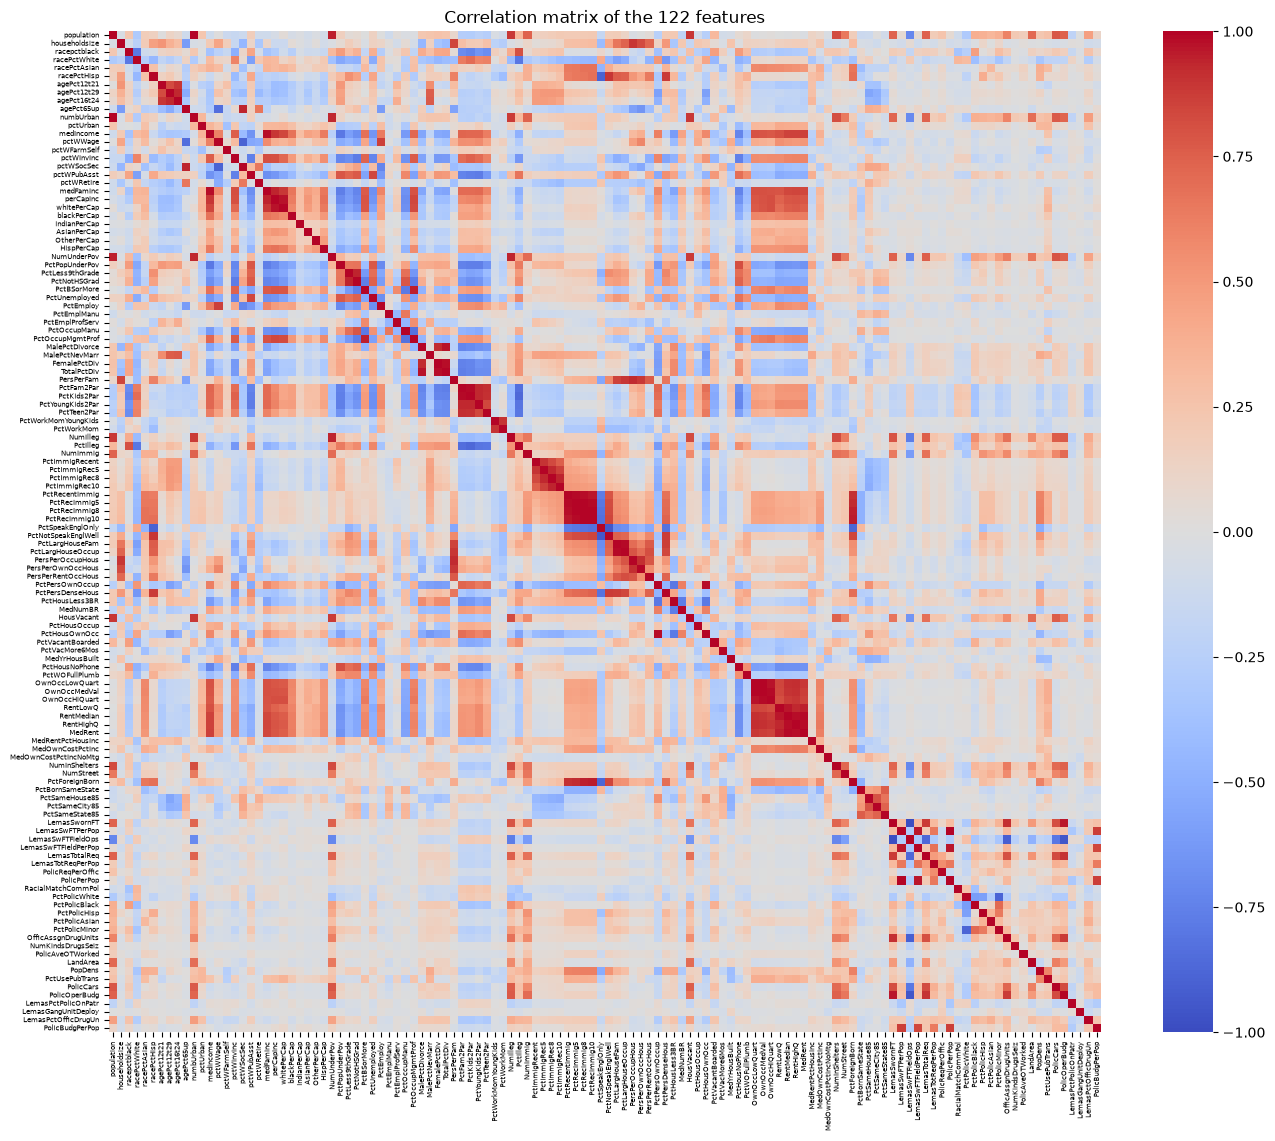

In [38]:
corr = X_all.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True)
plt.xticks(fontsize=5); plt.yticks(fontsize=5)
plt.title("Correlation matrix of the 122 features")
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [39]:
cv_values = X_all.std() / X_all.mean()
cv_table = cv_values.sort_values(ascending=False).to_frame("CV")
cv_table

,CV
PctPolicAsian,5.447835
NumStreet,4.407702
NumInShelters,3.485481
NumIlleg,2.994196
NumImmig,2.900497
...,...
NumKindsDrugsSeiz,0.143227
RacialMatchCommPol,0.126902
LemasPctPolicOnPatr,0.117807
PctPolicWhite,0.117726


### (e) Scatter plots and box plots for highest CV features

11 features: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


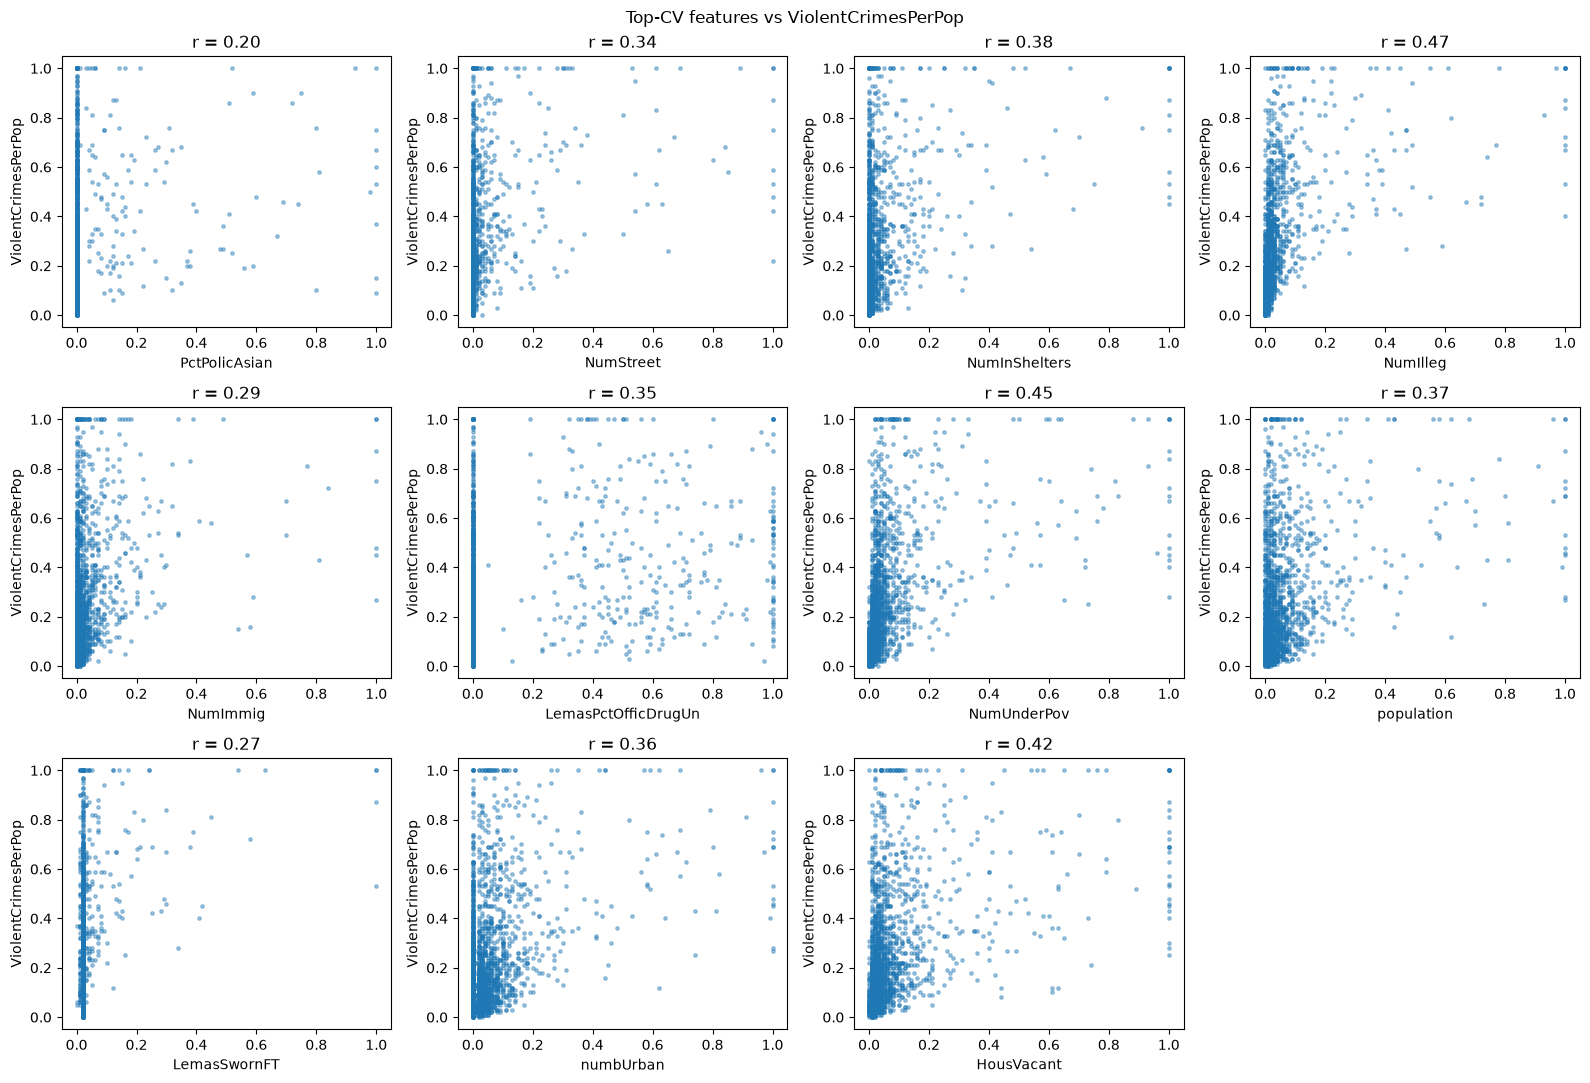

In [40]:
k = int(np.floor(np.sqrt(128)))
top_feats = cv_values.sort_values(ascending=False).index[:k].tolist()
print(k, "features:", top_feats)

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()
for i, f in enumerate(top_feats):
    axes[i].scatter(X_all[f], y_all, s=6, alpha=0.4)
    axes[i].set_xlabel(f); axes[i].set_ylabel(target)
    axes[i].set_title(f"r = {X_all[f].corr(y_all):.2f}")
axes[-1].axis("off")
plt.suptitle("Top-CV features vs ViolentCrimesPerPop")
plt.tight_layout(); plt.show()

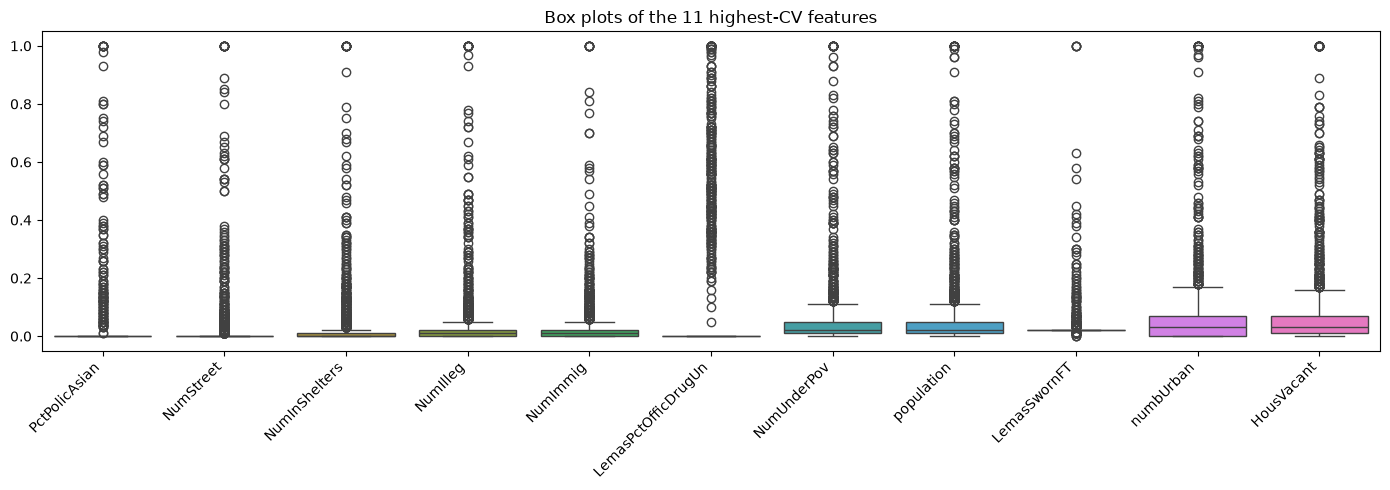

In [41]:
plt.figure(figsize=(14, 5))
sns.boxplot(data=X_all[top_feats])
plt.xticks(rotation=45, ha="right")
plt.title("Box plots of the 11 highest-CV features")
plt.tight_layout(); plt.show()

We cannot draw conclusions about the significance of these features just from the scatter plots because any visible trend is very weak, with much of the data bunched up. The box plots visualize this clearly, as much of what we might interpret as a 'trend' is due to the large values of the outliers.

### (f) Fit a linear model

In [42]:
lr = LinearRegression()
lr.fit(X_train, y_train)

mse_lr = mean_squared_error(y_test, lr.predict(X_test))
print("Linear regression test MSE:", round(mse_lr, 5))

Linear regression test MSE: 0.01797


### (g) Fit a ridge regression model

In [43]:
lambdas = np.logspace(-4, 4, 100)

ridge = RidgeCV(alphas=lambdas, cv=10, scoring="neg_mean_squared_error")
ridge.fit(X_train, y_train)

mse_ridge = mean_squared_error(y_test, ridge.predict(X_test))
print("Best lambda:", ridge.alpha_)
print("Ridge test MSE:", round(mse_ridge, 5))

Best lambda: 2.310129700083163
Ridge test MSE: 0.01752


### (h) Fit a LASSO model

In [44]:
kf = KFold(n_splits=10, shuffle=True, random_state=0)

lasso = LassoCV(cv=kf, random_state=0, max_iter=50000)
lasso.fit(X_train, y_train)

mse_lasso = mean_squared_error(y_test, lasso.predict(X_test))
selected = X.columns[lasso.coef_ != 0].tolist()

print("LASSO model:")
print("Best lambda:", lasso.alpha_)
print("LASSO test MSE:", round(mse_lasso, 5))
print(f"{len(selected)} variables selected:")
print(selected)

LASSO model:
Best lambda: 8.786112483379103e-05
LASSO test MSE: 0.01768
77 variables selected:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'medFamInc', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnC

In [45]:
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std  = scaler.transform(X_test)

lasso_std = LassoCV(cv=kf, random_state=0, max_iter=50000)
lasso_std.fit(X_train_std, y_train)

mse_lasso_std = mean_squared_error(y_test, lasso_std.predict(X_test_std))
selected_std = X.columns[lasso_std.coef_ != 0].tolist()

print("LASSO model with standardized features:")
print("Best lambda:", lasso_std.alpha_)
print("LASSO (standardized) test MSE:", round(mse_lasso_std, 5))
print(f"{len(selected_std)} variables selected:")
print(selected_std)

LASSO model with standardized features:
Best lambda: 0.0006189604623293166
LASSO (standardized) test MSE: 0.01773
76 variables selected:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPct

The test MSE for the non-standardized LASSO model was slightly lower (although nearly identical), at 0.01768 vs. 0.01773, which is to be expected since the features were already normalized.

### (i) Fit a PCR model

In [46]:
pcr = Pipeline([
    ("pca", PCA()),
    ("lr",  LinearRegression())
])

grid = {"pca__n_components": list(range(1, X_train.shape[1] + 1))}
pcr_search = GridSearchCV(pcr, grid, cv=kf, scoring="neg_mean_squared_error")
pcr_search.fit(X_train, y_train)

print("Best M:", pcr_search.best_params_["pca__n_components"])
print("PCR test MSE:", mean_squared_error(y_test, pcr_search.predict(X_test)))

Best M: 95
PCR test MSE: 0.01837400152090813


### (j) Fit a boosting tree

In [47]:
xgb = XGBRegressor(objective="reg:squarederror", random_state=0)

search = GridSearchCV(xgb, {"reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]},
                      cv=10, scoring="neg_mean_squared_error")
search.fit(X_train, y_train)

print("Best alpha:", search.best_params_["reg_alpha"])
print("Test MSE:", mean_squared_error(y_test, search.predict(X_test)))

Best alpha: 1
Test MSE: 0.017927099271879313
